# 07 — Génération des tuples UNSW-NB15 depuis un fichier PCAP

**Problème :** un modèle entraîné sur les 49 colonnes du CSV UNSW-NB15 est inutilisable sur une vraie capture
si l'on ne sait pas **calculer ces colonnes** à partir des paquets. La thèse de N. Moustafa (§3.5, Figure 3.4)
décrit la chaîne d'origine : Argus (flux) + Bro-IDS (journaux CONN/HTTP/FTP) + 12 features additionnelles
(Algorithmes 3.2 à 3.9), le tout appareillé sur le 5-tuple.

**Notre solution :** une réimplémentation en Python pur (`src/pcap/`) :

| Module | Rôle (équivalent thèse) |
|---|---|
| `reader.py` | lecture pcap / pcapng, décodage Ethernet/VLAN/SLL → IPv4/IPv6 → TCP/UDP/ICMP/ARP |
| `flows.py` | flux bidirectionnels **Argus** : état, octets, TTL, pertes, débits, gigue, RTT ; features additionnelles |
| `app_layer.py` | **Bro-IDS** : détection de service par signature, HTTP (trans_depth, res_bdy_len), FTP |
| `generator.py` | captures de démonstration avec vérité terrain par flux |

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


## 1. Validation des formules sur le CSV officiel

Avant d'écrire l'extracteur, nous avons **retrouvé empiriquement** les formules d'Argus en les confrontant
aux valeurs publiées (200 000 flux du fichier 1). Exemple : `sload` n'est pas `sbytes·8/dur` mais
`(sbytes − sbytes/spkts)·8/dur` — Argus ignore un paquet dans le calcul du débit.

In [2]:
from src.run_analysis import extractor_fidelity
fid = extractor_fidelity()

           feature                             formule  concordance_pct       n
0            sload       (sbytes − sbytes/spkts)·8/dur           99.235  198852
1            dload       (dbytes − dbytes/dpkts)·8/dur           99.860  178434
2          smeansz                 round(sbytes/spkts)          100.000  199998
3          dmeansz                 round(dbytes/dpkts)          100.000  178704
4           tcprtt                     synack + ackdat          100.000  200000
5     ct_state_ttl  Algorithme 3.3 (règles TTL × état)           99.980  200000
6  is_sm_ips_ports                      Algorithme 3.2           99.973  200000
7       swin (TCP)    min(fenêtre du 1er segment, 255)           99.992  131656


In [3]:
from src.preprocessing import read_raw_file, clean_dataframe
d = clean_dataframe(read_raw_file(C.RAW_FILES[0], nrows=200000))
d = d[(d.dur > 0) & (d.spkts > 1)]
naive = (np.abs(d.sbytes * 8 / d.dur - d.sload) <= 0.01 * d.sload).mean()
argus = (np.abs((d.sbytes - d.sbytes / d.spkts) * 8 / d.dur - d.sload) <= 0.01 * d.sload).mean()
print(f"sload = sbytes·8/dur : {naive:.1%} de concordance   |   (sbytes − sbytes/spkts)·8/dur : {argus:.1%}")

sload = sbytes·8/dur : 6.1% de concordance   |   (sbytes − sbytes/spkts)·8/dur : 99.2%


**Limite assumée :** les compteurs `ct_*` (fenêtres de 100 connexions) ne se reproduisent qu'approximativement :
le CSV publié ne contient qu'un sous-ensemble des enregistrements Argus et leur ordre exact n'est pas documenté.
Nous implémentons la lecture « blocs de 100 enregistrements triés par `ltime` » de l'Algorithme 3.7
(la plus proche des valeurs publiées) et une variante en fenêtre glissante.

## 2. Captures de démonstration

Faute de pouvoir versionner les 100 Go de PCAP originaux, `generator.py` synthétise du trafic reproduisant la
topologie du banc de test (clients 59.166.0.0/24 en TTL 31, serveurs 149.171.126.0/24, attaquants
175.45.176.0/24 en TTL 254/62) : HTTP, DNS, FTP (+ ftp-data), SSH, SMTP et les 9 familles d'attaques, avec
une **vérité terrain par flux**. Une seconde capture utilise des TTL d'hôtes modernes (64/128).

In [4]:
from src.pcap.generator import generate_demo_pcap, match_ground_truth
from src.pcap import pcap_to_flows
for name, kw in [('demo_unsw_testbed', {}), ('demo_modern_ttl', dict(seed=7, testbed_ttl=False, n_normal=120, n_attack_each=8))]:
    p = C.SAMPLE_PCAP_DIR / f'{name}.pcap'
    if not p.exists():
        generate_demo_pcap(p, **kw)
    print(name, f"{p.stat().st_size / 1e6:.2f} Mo")
import time; t = time.time()
flows = pcap_to_flows(C.SAMPLE_PCAP_DIR / 'demo_unsw_testbed.pcap')
print(f"{flows.attrs['n_packets']:,} paquets → {len(flows)} tuples de {flows.shape[1]} features en {time.time() - t:.2f}s")
display(flows.head(8))

demo_unsw_testbed 1.18 Mo
demo_modern_ttl 0.94 Mo
4,155 paquets → 428 tuples de 47 features en 0.07s


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,service,sload,dload,spkts,dpkts,swin,dwin,stcpb,dtcpb,smeansz,dmeansz,trans_depth,res_bdy_len,sjit,djit,stime,ltime,sintpkt,dintpkt,tcprtt,synack,ackdat,is_sm_ips_ports,ct_state_ttl,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm
0,175.45.176.1,50042,149.171.126.10,80,tcp,FIN,0.050106,824,162,254,252,0,0,http,105248.770339,17243.427179,5,3,255,255,223342723,936659286,165,54,1,0,10.591238,3.053069,1421927414,1421927414,12.526512,24.052978,0.002,0.001,0.001,0,1,1,0,0,12,11,30,21,15,1,16
1,175.45.176.1,52322,149.171.126.10,80,tcp,FIN,0.040016,626,162,254,252,0,0,http,100120.112403,21591.398042,5,3,255,255,1751764887,1863787097,125,54,1,0,8.355702,1.991868,1421927414,1421927414,10.003984,19.008040,0.002,0.001,0.001,0,1,1,0,0,12,11,30,21,15,1,16
2,175.45.176.1,24334,149.171.126.10,80,tcp,FIN,0.032546,666,162,254,252,0,0,http,130965.228189,26547.005714,5,3,255,255,843141168,1696598165,133,54,1,0,7.940593,5.726933,1421927414,1421927414,8.136511,15.272975,0.002,0.001,0.001,0,1,1,0,0,12,11,30,21,15,1,16
3,175.45.176.1,39071,149.171.126.10,80,tcp,FIN,0.039937,523,162,254,252,0,0,http,83811.963302,21634.063185,5,3,255,255,579489697,2006488007,105,54,1,0,8.344737,2.031565,1421927414,1421927414,9.984255,18.968582,0.002,0.001,0.001,0,1,1,0,0,12,11,30,21,15,1,16
4,175.45.176.1,37737,149.171.126.10,80,udp,INT,0.160000,922,0,254,0,0,0,-,40977.755796,0.000000,9,0,0,0,0,0,102,0,0,0,0.000079,0.000000,1421927414,1421927414,20.000011,0.000000,0.000,0.000,0.000,0,2,0,0,0,4,11,30,21,15,1,16
5,59.166.0.7,2712,149.171.126.14,53,udp,CON,0.001000,78,94,31,29,0,0,dns,0.000000,0.000000,1,1,0,0,0,0,78,94,0,0,0.000000,0.000000,1421927415,1421927415,0.000000,0.000000,0.000,0.000,0.000,0,0,0,0,0,1,3,5,5,1,1,1
6,175.45.176.0,51222,149.171.126.12,4444,tcp,FIN,0.038113,552,240,254,252,0,0,-,96555.288289,37782.504113,6,4,255,255,796860564,483685168,92,60,0,0,5.610246,1.942616,1421927416,1421927416,7.622576,12.037675,0.002,0.001,0.001,0,1,0,0,0,2,10,24,5,1,1,3
7,59.166.0.5,35271,149.171.126.19,53,udp,CON,0.001000,79,95,31,29,0,0,dns,0.000000,0.000000,1,1,0,0,0,0,79,95,0,0,0.000000,0.000000,1421927417,1421927417,0.000000,0.000000,0.000,0.000,0.000,0,0,0,0,0,1,2,5,3,1,1,1


In [5]:
lab = pd.read_csv(C.SAMPLE_PCAP_DIR / 'demo_unsw_testbed_labels.csv')
m = match_ground_truth(flows, lab)
display(m.groupby('true_attack_cat')[['proto', 'state', 'service']].agg(lambda s: s.value_counts().index[0]))
display(m.groupby('true_attack_cat')[['dur', 'sbytes', 'dbytes', 'spkts', 'sttl', 'dttl', 'ct_state_ttl', 'smeansz', 'ct_srv_src']].median().round(4))

,proto,state,service
true_attack_cat,,,
Analysis,unas,INT,-
Backdoor,unas,INT,-
DoS,tcp,FIN,http
Exploits,tcp,FIN,http
Fuzzers,tcp,FIN,-
Generic,udp,INT,dns
Normal,tcp,FIN,http
Reconnaissance,tcp,RST,-
Shellcode,tcp,FIN,-


,dur,sbytes,dbytes,spkts,sttl,dttl,ct_state_ttl,smeansz,ct_srv_src
true_attack_cat,,,,,,,,,
Analysis,0.0000,400.0,0.0,2.0,254.0,0.0,2.0,200.0,9.0
Backdoor,0.0000,400.0,0.0,2.0,254.0,0.0,2.0,200.0,8.0
DoS,0.0512,793.0,162.0,5.0,254.0,252.0,1.0,138.0,11.0
Exploits,0.0377,420.0,294.0,6.0,62.0,252.0,1.0,70.0,5.0
Fuzzers,0.0392,1104.0,234.0,6.0,254.0,252.0,1.0,184.0,9.0
Generic,0.0000,126.0,0.0,2.0,254.0,0.0,2.0,63.0,5.0
Normal,0.0561,632.0,2993.5,8.0,31.0,29.0,0.0,79.0,2.0
Reconnaissance,0.0003,54.0,54.0,1.0,254.0,252.0,0.0,54.0,11.0
Shellcode,0.0382,701.0,240.0,6.0,254.0,252.0,1.0,117.0,4.0


## 3. Test aller-retour sur du trafic réel : rejeu d'enregistrements UNSW-NB15

Les scénarios ci-dessus sont écrits à la main : leurs « attaques » ne reproduisent pas le comportement
des attaques générées par IXIA dans le banc de test. Pour valider la chaîne sur un trafic **réel**, on rejoue
une tranche contiguë de 2 500 enregistrements du CSV officiel (fichier 4, toutes les familles d'attaques) :
pour chaque enregistrement, `src/pcap/replay.py` reconstruit les paquets qui le produisent (mêmes IP,
ports, TTL, nombres de paquets et d'octets, durée, délais de poignée de main, état, signature applicative).
Le PCAP est tronqué à 160 octets par trame (comme `tcpdump -s 160`) : l'extracteur lit les longueurs dans
les en-têtes IP, ce qui le rend aussi robuste aux vraies captures tronquées.

**Question 1 — fidélité :** les features ré-extraites sont-elles égales aux valeurs d'origine ?

2496 enregistrements rejoués → 72,092 paquets → 1450 flux ré-extraits


,feature,critere,concordance_pct,n
0,state,identique,99.76,837
1,service,identique,94.98,837
2,sbytes,±2 %,99.16,837
3,dbytes,±2 %,95.34,837
4,spkts,±2 %,100.00,837
5,dpkts,±2 %,100.00,837
6,sttl,±2 %,100.00,837
7,dttl,±2 %,100.00,837
8,dur,±2 %,100.00,837
9,smeansz,±2 %,99.64,837


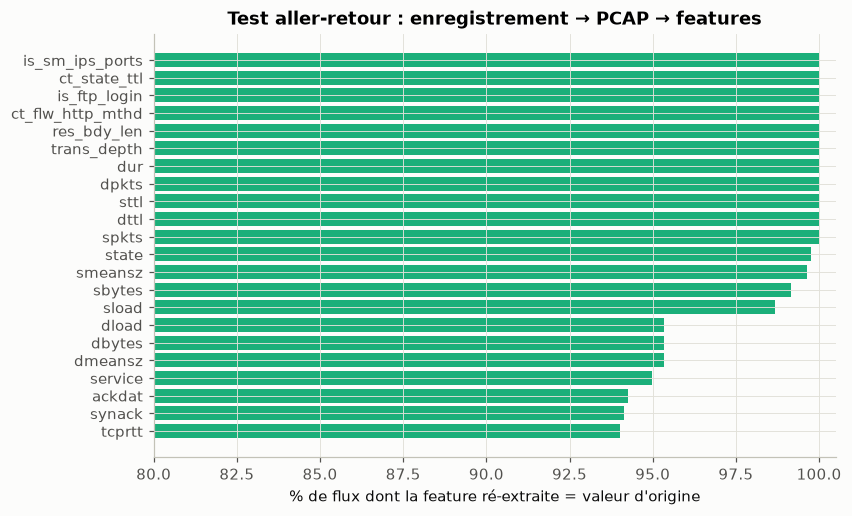

In [6]:
from src.pcap.replay import build_replay_demos, roundtrip_fidelity
if not (C.SAMPLE_PCAP_DIR / 'demo_unsw_replay.pcap').exists():
    build_replay_demos()
rec = pd.read_csv(C.SAMPLE_PCAP_DIR / 'demo_unsw_replay_records.csv', low_memory=False)
fl_r = pcap_to_flows(C.SAMPLE_PCAP_DIR / 'demo_unsw_replay.pcap')
print(f"{len(rec)} enregistrements rejoués → {fl_r.attrs['n_packets']:,} paquets → {len(fl_r)} flux ré-extraits")
fid_rt = roundtrip_fidelity(rec, fl_r)
display(fid_rt)
fig, ax = plt.subplots(figsize=(8, 5))
s_ = fid_rt.sort_values('concordance_pct')
ax.barh(s_.feature, s_.concordance_pct, color=V.SERIES[2]); ax.set_xlim(80, 100.5)
ax.set_xlabel("% de flux dont la feature ré-extraite = valeur d'origine"); ax.set_title('Test aller-retour : enregistrement → PCAP → features')
V.save(fig, '07_replay_fidelity'); plt.show()

**Lecture :** état, nombres de paquets, TTL, durée, profondeur HTTP, taille des corps de réponse, `ct_state_ttl`
sont reproduits à 99–100 %. Les écarts restants (≈ 5 %) viennent de flux TCP atypiques (retransmissions,
poignées de main incomplètes) que le rejeu simplifie. Les flux `unas` sont moins nombreux que les
enregistrements : Argus nomme « unas » tous les numéros de protocole IP non assignés ; le balayage de
protocoles du banc de test réutilise ces 110 numéros et les répétitions rapprochées fusionnent.

**Question 2 — détection de bout en bout, et artefact TTL.** On évalue les modèles déployés sur le rejeu,
puis sur le **même trafic** dont les TTL sont remplacés par 64 (hôtes modernes). On distingue les flux dont
l'enregistrement d'origine n'a **jamais été vu à l'entraînement**.

  demo_unsw_replay         full     tous les flux                n= 1450 F1=0.870 rappel=0.873 FPR=0.045 type=0.719
  demo_unsw_replay         full     jamais vus à l'entraînement  n= 1010 F1=0.787 rappel=1.000 FPR=0.050 type=0.953


  demo_unsw_replay         portable tous les flux                n= 1450 F1=0.936 rappel=1.000 FPR=0.046 type=0.730
  demo_unsw_replay         portable jamais vus à l'entraînement  n= 1010 F1=0.783 rappel=1.000 FPR=0.051 type=0.929


  demo_unsw_replay_ttl64   full     tous les flux                n= 1450 F1=0.005 rappel=0.003 FPR=0.000 type=0.000
  demo_unsw_replay_ttl64   full     jamais vus à l'entraînement  n= 1010 F1=0.023 rappel=0.012 FPR=0.000 type=0.000
  demo_unsw_replay_ttl64   portable tous les flux                n= 1450 F1=0.936 rappel=1.000 FPR=0.046 type=0.730
  demo_unsw_replay_ttl64   portable jamais vus à l'entraînement  n= 1010 F1=0.783 rappel=1.000 FPR=0.051 type=0.929


  demo_unsw_testbed        full     tous les flux                n=  428 F1=0.861 rappel=0.755 FPR=0.000 type=0.288
  demo_unsw_testbed        portable tous les flux                n=  428 F1=0.495 rappel=0.347 FPR=0.097 type=0.000


  demo_modern_ttl          full     tous les flux                n=  316 F1=0.000 rappel=0.000 FPR=0.000 type=0.000
  demo_modern_ttl          portable tous les flux                n=  316 F1=0.480 rappel=0.351 FPR=0.160 type=0.000


,description,profile,subset,n_flows,n_attacks,precision,recall,f1,false_alarm_rate,attack_type_accuracy
0,Rejeu d'enregistrements réels UNSW-NB15 (TTL d...,full,tous les flux,1450,363,0.866,0.873,0.870,0.045,0.719
1,Rejeu d'enregistrements réels UNSW-NB15 (TTL d...,full,jamais vus à l'entraînement,1010,85,0.649,1.000,0.787,0.050,0.953
2,Rejeu d'enregistrements réels UNSW-NB15 (TTL d...,portable,tous les flux,1450,363,0.879,1.000,0.936,0.046,0.730
3,Rejeu d'enregistrements réels UNSW-NB15 (TTL d...,portable,jamais vus à l'entraînement,1010,85,0.644,1.000,0.783,0.051,0.929
4,"Même rejeu, TTL d'hôtes modernes (64)",full,tous les flux,1450,363,1.000,0.003,0.005,0.000,0.000
5,"Même rejeu, TTL d'hôtes modernes (64)",full,jamais vus à l'entraînement,1010,85,1.000,0.012,0.023,0.000,0.000
6,"Même rejeu, TTL d'hôtes modernes (64)",portable,tous les flux,1450,363,0.879,1.000,0.936,0.046,0.730
7,"Même rejeu, TTL d'hôtes modernes (64)",portable,jamais vus à l'entraînement,1010,85,0.644,1.000,0.783,0.051,0.929
8,Scénarios synthétiques (topologie du banc de t...,full,tous les flux,428,274,1.000,0.755,0.861,0.000,0.288
9,Scénarios synthétiques (topologie du banc de t...,portable,tous les flux,428,274,0.864,0.347,0.495,0.097,0.000


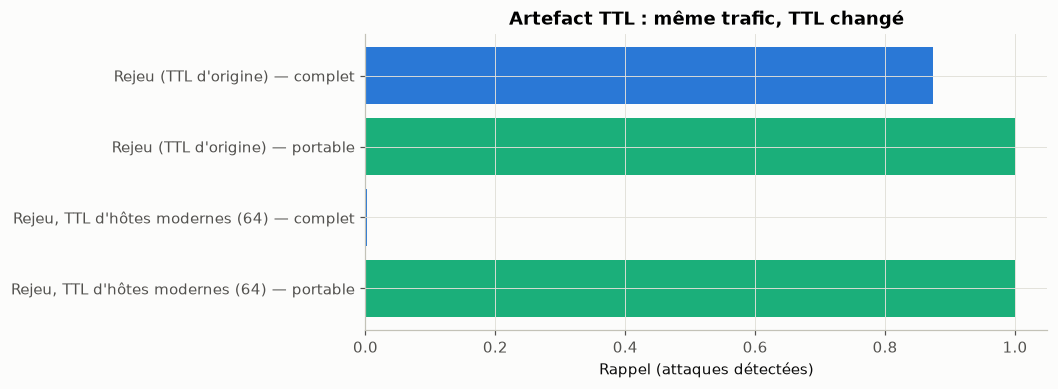

In [7]:
from src import run_analysis as RA
e2e = pd.DataFrame(RA.pcap_end_to_end())
display(e2e[['description', 'profile', 'subset', 'n_flows', 'n_attacks', 'precision', 'recall', 'f1', 'false_alarm_rate', 'attack_type_accuracy']].round(3))
rp = e2e[e2e.pcap.str.startswith('demo_unsw_replay') & (e2e.subset == 'tous les flux')]
fig, ax = plt.subplots(figsize=(8, 3.5))
lab_ = rp.description.str.replace("Rejeu d'enregistrements réels UNSW-NB15 ", 'Rejeu ').str.replace('Même rejeu, ', 'Rejeu, ') + ' — ' + rp.profile.map({'full': 'complet', 'portable': 'portable'})
ax.barh(lab_, rp.recall, color=[V.SERIES[0] if p == 'full' else V.SERIES[2] for p in rp.profile])
ax.set_xlim(0, 1.05); ax.set_xlabel('Rappel (attaques détectées)'); ax.invert_yaxis(); ax.set_title('Artefact TTL : même trafic, TTL changé')
V.save(fig, '07_ttl_artifact'); plt.show()

**Lecture :**
- Sur le trafic rejoué avec ses TTL d'origine, la chaîne complète détecte les attaques (rappel ≈ 0,9–1,0) et donne le
  **type d'attaque** exact pour la grande majorité d'entre elles, y compris sur les flux jamais vus.
- Avec des TTL de 64, le profil **complet s'effondre** (il a appris « TTL 254 ⇒ attaque », propriété du banc de test),
  alors que le profil **portable** garde exactement les mêmes performances : c'est le profil à utiliser sur un autre réseau.
- Les scénarios synthétiques, dont les attaques sont inventées, sont nettement moins bien reconnus : un modèle
  appris sur UNSW-NB15 reconnaît les attaques *du banc de test*, pas n'importe quel trafic anormal (d'où l'intérêt
  complémentaire des détecteurs d'anomalies du notebook 04).

## 4. Utilisation sur les PCAP originaux de UNSW-NB15
Les 100 Go de PCAP sont téléchargeables sur le site officiel. Pour un fichier :
```python
flows = pcap_to_flows('chemin/vers/1.pcap')     # 47 colonnes, ordre officiel
flows.to_csv('1_tuples.csv', index=False)
```
ou directement via la page **Analyse PCAP** de l'application (téléversement jusqu'à 200 Mo).